# 03 — Baselines

**Question:** how well can next week be forecast from past seismicity alone? These simple forecasts set the bar: the paper's model (later in this notebook) and the machine-learning models of phase 6 are only useful if they beat them.

**Setup** (`src/evaluation.py`):

- **Targets**, per week (Monday to Sunday, UTC): the number of events with M ≥ 0.6 (`MC_MAIN`, from `01_completeness`), and whether the week had at least one event with M ≥ 3.
- **Walk-forward evaluation:** each test week is forecast using only the weeks before it, then the window moves on by one week. Nothing is shuffled, and no forecast sees its own week or later.
- **Test period:** January 2020 to December 2025 (312 weeks). Before 2020 most weeks have no events, which would make scores easy and uninformative; the GPS record ends in December 2025. History for every forecast starts in January 2005. Results for 2023–2025, the busiest years, are also shown separately.
- **Scores:**
  - Counts: **Poisson deviance**, the standard score for count forecasts (0 is perfect, lower is better; it punishes forecasting too few events in a busy week heavily, and forecasting zero when events happen infinitely, so forecasts are floored at 0.1 events), and **mean absolute error** (MAE) in events per week, which is easier to read.
  - M ≥ 3: **Brier score** (mean squared error of the probability) and **log-loss** (penalises confident wrong forecasts heavily), both lower is better; and **calibration**: when we say 20%, does it happen about 20% of the time?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.baselines import (make_climatology, make_from_count, make_rolling_mean, make_trend,
                           persistence)
from src.evaluation import (calibration_table, count_scores, probability_scores,
                            walk_forward, weekly_targets)

events = pd.read_parquet("../data/processed/catalogue.parquet")
weekly = weekly_targets(events, start="2005-01-03", end="2025-12-28")
TEST_START, TEST_END = "2020-01-06", "2025-12-22"
test = weekly.loc[TEST_START:TEST_END]
print(f"History from {weekly.index[0]:%Y-%m-%d}; {len(test)} test weeks "
      f"{test.index[0]:%Y-%m-%d} to {test.index[-1]:%Y-%m-%d}")
test.groupby(test.index.year).agg(weeks=("count", "size"), events=("count", "sum"),
                                  median_per_week=("count", "median"),
                                  max_per_week=("count", "max"),
                                  weeks_with_M3=("has_large", "sum"))

History from 2005-01-03; 312 test weeks 2020-01-06 to 2025-12-22


,weeks,events,median_per_week,max_per_week,weeks_with_M3
period_start,,,,,
2020,52,148,1.5,19,1
2021,52,165,2.0,19,0
2022,52,299,5.5,32,2
2023,52,918,10.5,126,10
2024,53,1452,17.0,160,14
2025,51,2189,28.0,334,16


## 1. Forecasting the weekly count

Five baselines (`src/baselines.py`):

- **Persistence:** next week = this week.
- **Rolling mean, 4 or 12 weeks:** next week = the average of the last 4 or 12 weeks.
- **Trend, 52 or 104 weeks:** a Poisson regression of weekly counts on time over the last one or two years, extrapolated one week ahead. Phase 4 showed the rate doubling about every 1.5 years; this baseline uses that.

In [2]:
count_forecasters = [persistence, make_rolling_mean(4), make_rolling_mean(12),
                     make_trend(52), make_trend(104)]
count_forecasts = {f.__name__: walk_forward(weekly, f, TEST_START, TEST_END) for f in count_forecasters}

recent = test.index >= "2023-01-01"
pd.concat({
    "2020–2025": count_scores(test["count"], count_forecasts),
    "2023–2025": count_scores(test["count"][recent], {n: f[recent] for n, f in count_forecasts.items()}),
}, axis=1).round(2)

2020–2025               2023–2025       
                 poisson_deviance    mae poisson_deviance    mae
persistence                 15.99  12.16            24.11  20.70
rolling_mean_4w             14.81  12.07            25.35  21.26
rolling_mean_12w            17.70  12.79            30.82  22.48
trend_52w                   19.38  13.70            34.04  24.14
trend_104w                  17.21  13.43            30.11  23.75

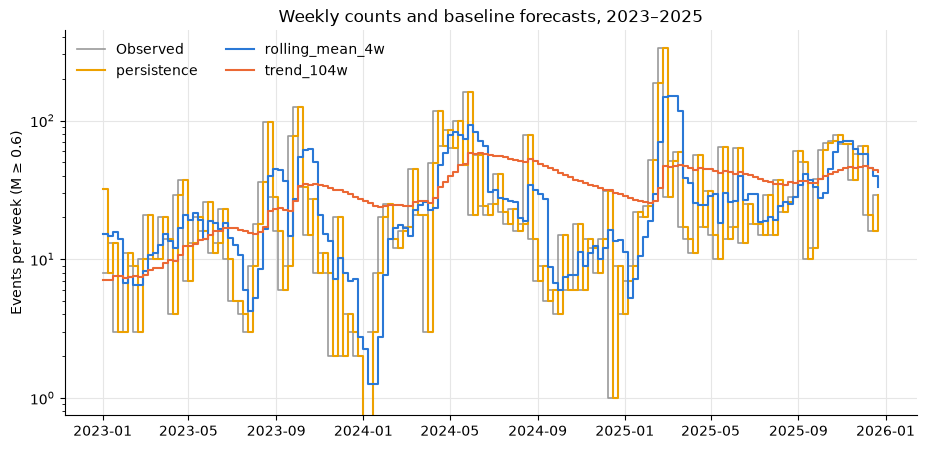

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
shown = test.loc["2023-01-01":]
ax.plot(shown.index, shown["count"].where(shown["count"] > 0), drawstyle="steps-post", color="0.6",
        linewidth=1.2, label="Observed")
for name, colour in [("persistence", "#eda100"), ("rolling_mean_4w", "#2a78d6"), ("trend_104w", "#eb6834")]:
    f = count_forecasts[name].loc["2023-01-01":]
    ax.plot(f.index, f, drawstyle="steps-post", linewidth=1.5, color=colour, label=name)
ax.set_yscale("log")
ax.set_ylabel("Events per week (M ≥ 0.6)")
ax.set_title("Weekly counts and baseline forecasts, 2023–2025")
ax.grid(True, which="major", color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.show()

## 2. Forecasting P(at least one M ≥ 3 next week)

- **Climatology:** the share of past weeks with an M ≥ 3 event, over all history or the last 52 weeks.
- **From a count forecast:** P = 1 − exp(−expected count × share), where share is the fraction of events with M ≥ 0.6 that reached M ≥ 3 over the last 3 years. This assumes events within a week are independent, which swarms violate; it uses the observed share rather than a Gutenberg–Richter b-value (which phase 4 found underpredicts large events).

For reference: 43 of the 312 test weeks (13.8%) had an M ≥ 3 event. A forecaster that always said 13.8% would score Brier 0.119, but it would be cheating, since it uses the answer.

In [4]:
prob_forecasters = [make_climatology(), make_climatology(52),
                    make_from_count(make_rolling_mean(4)), make_from_count(make_rolling_mean(12)),
                    make_from_count(make_trend(104))]
prob_forecasts = {f.__name__: walk_forward(weekly, f, TEST_START, TEST_END) for f in prob_forecasters}

pd.concat({
    "2020–2025": probability_scores(test["has_large"], prob_forecasts),
    "2023–2025": probability_scores(test["has_large"][recent], {n: p[recent] for n, p in prob_forecasts.items()}),
}, axis=1).round(3)

2020–2025                 2023–2025                
                          brier log_loss mean_p     brier log_loss mean_p
climatology_all           0.132    0.573  0.012     0.245    1.025  0.021
climatology_52w           0.107    0.357  0.118     0.195    0.597  0.213
from_rolling_mean_4w      0.107    0.335  0.150     0.194    0.576  0.277
from_rolling_mean_12w     0.114    0.355  0.154     0.209    0.611  0.286
from_trend_104w           0.115    0.359  0.179     0.211    0.615  0.334

In [5]:
# Calibration of the best baseline: do forecast probabilities match how often M >= 3 happened?
calibration_table(test["has_large"], prob_forecasts["from_rolling_mean_4w"]).round(3)

,weeks,mean_forecast,observed_share
forecast_bin,,,
"(-0.001, 0.05]",157,0.021,0.019
"(0.05, 0.1]",45,0.071,0.111
"(0.1, 0.2]",26,0.146,0.192
"(0.2, 0.3]",19,0.251,0.368
"(0.3, 1.0]",65,0.489,0.354


**What the baselines show:**

- **Counts: short memory wins.** The 4-week rolling mean scores best over 2020–2025 (Poisson deviance 14.8, MAE 12.1 events/week), with persistence close behind (16.0) and even slightly better in 2023–2025 (24.1 vs 25.4). Longer windows and the trend models do worse: after a swarm they stay high for months (the trend lines in the plot), and they react slowly to sudden changes. The rate changes faster than any smooth trend.
- **Errors are large.** An MAE of 12 events/week (20 in 2023–2025) against a median of 10–28 events/week shows how bursty the seismicity is: swarms arrive with little warning in the count series itself. The plot shows persistence as the observed series shifted by one week; it is always one swarm late.
- **M ≥ 3: the 4-week count turned into a probability is best** (Brier 0.107, log-loss 0.335), just ahead of the 52-week climatology. Climatology over all history is poor (it averages in the quiet early years and forecasts about 1%).
- **Calibration is decent at low probabilities but off at the top:** weeks forecast below 5% had an M ≥ 3 2% of the time (forecast 2%), but weeks forecast above 30% (mean 49%) had one only 35% of the time, and the middle bins are under-forecast. The Poisson conversion is over-confident after big swarms, when many events but not proportionally many M ≥ 3 follow.

**The bar for later models:** Poisson deviance 14.8 (2020–2025) and 24.1 (2023–2025) for counts; Brier 0.107 and log-loss 0.335 for M ≥ 3. Next in this notebook: the paper's model.